In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROC = Path("../data/processed")
FIG = Path("../outputs/figures")
TAB = Path("../outputs/tables")

PERIODS = ["Pre-COVID", "During-COVID", "Post-COVID"]

df = pd.read_csv(PROC / "wfp_prices_tagged.csv", parse_dates=["date"])
df["ym"] = df["date"].dt.to_period("M")
df["period"] = pd.Categorical(df["period"], PERIODS, ordered=True)
print(df.shape)

(210339, 18)


In [2]:
print(df.groupby("pricetype").agg(rows=("price", "size"),
                                  markets=("market_id", "nunique"),
                                  commodities=("commodity_id", "nunique"),
                                  start=("date", "min"),
                                  end=("date", "max")))

retail = df[df["pricetype"] == "Retail"].copy()
retail.to_csv(PROC / "wfp_retail_tagged.csv", index=False)
print("\nRetail rows kept:", len(retail))

             rows  markets  commodities      start        end
pricetype                                                    
Retail     207724       97           64 2016-01-15 2026-06-15
Wholesale    2615       17           12 2016-01-15 2020-02-15

Retail rows kept: 207724


In [3]:
# From Step 2: June 2019 - Feb 2020 is too thin to count as "Pre-COVID" coverage
SOLID_PRE_END = pd.Period("2019-05", freq="M")

solid = retail[(retail["period"] != "Pre-COVID") | (retail["ym"] <= SOLID_PRE_END)].copy()

denom = solid.groupby("period", observed=True)["ym"].nunique()
print("Months with data per period:")
print(denom)

Months with data per period:
period
Pre-COVID       41
During-COVID    37
Post-COVID      37
Name: ym, dtype: int64


In [4]:
pres = (solid.groupby(["market_id", "market", "admin1", "period"], observed=True)
             .size().unstack("period").notna())
pres["n_periods"] = pres[PERIODS].sum(axis=1)

print("Markets by number of periods present:")
print(pres["n_periods"].value_counts().sort_index())

print("\nMarkets present in ALL three periods:")
display(pres[pres["n_periods"] == 3])

print("\nMarkets per period:")
print(solid.groupby("period", observed=True)["market_id"].nunique())

Markets by number of periods present:
n_periods
1    14
2    80
3     3
Name: count, dtype: int64

Markets present in ALL three periods:


,,period,Pre-COVID,During-COVID,Post-COVID,n_periods
market_id,market,admin1,,,,
167,Metro Manila,National Capital region,True,True,True,3
178,Zamboanga City,Region IX,True,True,True,3
180,Davao City,Region XI,True,True,True,3



Markets per period:
period
Pre-COVID       17
During-COVID    83
Post-COVID      83
Name: market_id, dtype: int64


In [5]:
reg_mk = (solid.groupby(["admin1", "period"], observed=True)["market_id"]
               .nunique().unstack("period").fillna(0).astype(int))
display(reg_mk)
print("Regions present in all three periods:", int((reg_mk > 0).all(axis=1).sum()))
reg_mk.to_csv(TAB / "03_markets_per_region_period.csv")

period,Pre-COVID,During-COVID,Post-COVID
admin1,,,
Autonomous region in Muslim Mindanao,1,5,5
Cordillera Administrative region,1,6,6
National Capital region,1,1,1
Region I,1,4,4
Region II,1,4,4
Region III,1,7,7
Region IV-A,1,5,5
Region IV-B,1,5,5
Region IX,1,4,4


Regions present in all three periods: 17


In [6]:
THRESH = 0.80   # a series "passes" if >= 80% of months have data in EACH period

cov = (solid.groupby(["admin1", "commodity", "period"], observed=True)["ym"]
            .nunique().unstack("period").fillna(0))
cov = cov.div(denom, axis=1)
cov["min_cov"] = cov[PERIODS].min(axis=1)
cov["passes"] = cov["min_cov"] >= THRESH

print("Passing series (region x commodity):", int(cov["passes"].sum()))
print("Regions with at least one passing series:",
      cov[cov["passes"]].index.get_level_values("admin1").nunique())

core = (cov[cov["passes"]].reset_index()
           .groupby("commodity").agg(regions=("admin1", "nunique"))
           .sort_values("regions", ascending=False))
display(core)

cov.to_csv(TAB / "03_commodity_region_coverage.csv")
core.to_csv(TAB / "03_core_commodities.csv")

Passing series (region x commodity): 111
Regions with at least one passing series: 16


,regions
commodity,
"Meat (chicken, whole)",16
Onions (red),16
"Rice (regular, milled)",16
Meat (pork),15
"Meat (beef, chops with bones)",14
Tomatoes,7
Carrots,7
Cabbage,5
Garlic,4


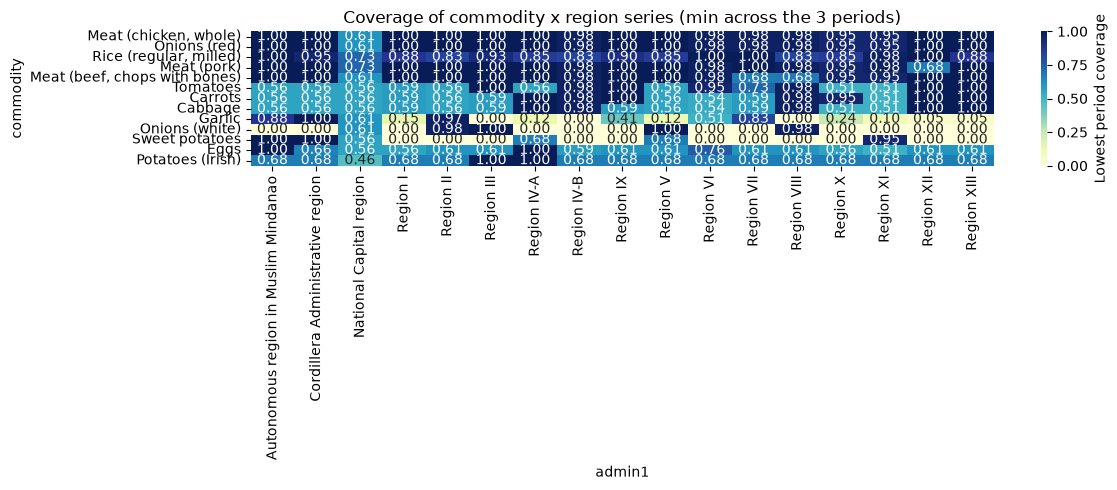

In [7]:
heat = (cov["min_cov"].unstack("admin1").loc[core.index])
plt.figure(figsize=(12, 5))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
            cbar_kws={"label": "Lowest period coverage"})
plt.title("Coverage of commodity x region series (min across the 3 periods)")
plt.tight_layout()
plt.savefig(FIG / "03_core_coverage_heatmap.png", dpi=150)
plt.show()